## 1. Setup

In [1]:
# Run once, then restart the kernel if pip installs anything new
%pip install -q torch torchvision scikit-learn pandas matplotlib pillow tqdm

Note: you may need to restart the kernel to use updated packages.


In [14]:
import random, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# ---------------- SETTINGS (edit here) ----------------
DATA_DIR_NAME = "matfuse_1"      # folder name; the notebook searches upwards from here to find it
DATA_DIR_FALLBACK = Path(r"C:\Users\ugome\OneDrive\Documents\hackathon-team7-MINC_2500_material_patches\matfuse_1")
SUBFOLDER = "sample_materials"   # images live in DATA_DIR/SUBFOLDER (use "" for the whole folder)
NAME_FILTER = None               # e.g. "diffuse" keeps only filenames containing that text

IMG_SIZE    = 224
BATCH_SIZE  = 16
EPOCHS      = 15
LR          = 3e-4
NUM_WORKERS = 0                  # keep 0 on Windows
SEED        = 42

PIXELATE_TRAIN = False           # randomly pixelate training images (wood vs brick problem)
PIXELATE_TEST  = False           # pixelate test images too, to check robustness
# ------------------------------------------------------

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


### 2 Find the Dataset
The dataset is cloned into `data/` inside this project. This cell adds it to `.gitignore` so it never shows up as thousands of changed files in Source Control.

In [ ]:
def find_dir(name):
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / name).is_dir():
            return p / name
    return None

DATA_DIR = find_dir(DATA_DIR_NAME) or DATA_DIR_FALLBACK
DATA_ROOT = DATA_DIR / SUBFOLDER if SUBFOLDER else DATA_DIR
print("Dataset folder:", DATA_ROOT, "| exists:", DATA_ROOT.exists())

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
files = [p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in IMG_EXT and ".git" not in p.parts]
if NAME_FILTER:
    files = [p for p in files if NAME_FILTER.lower() in p.name.lower()]
print("Images found:", len(files))
for folder, n in Counter(p.parent.relative_to(DATA_ROOT) for p in files).most_common(15):
    print(f"  {n:>5}  {folder}")

.gitignore now ignores: ['data/', 'checkpoints/', '*.pt']


## 3. Build the dataset

In [16]:
DATA_DIR = Path(r"C:\Users\ugome\OneDrive\Documents\hackathon-team7-MINC_2500_material_patches\matfuse_1")
DATA_ROOT = DATA_DIR / "sample_materials"

In [18]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
files = [p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in IMG_EXT]

30 images, 5 classes
label
asphalt_floor     6
castle_brick      6
clean_pebbles     6
grey_roof         6
old_wood_floor    6
Name: count, dtype: int64


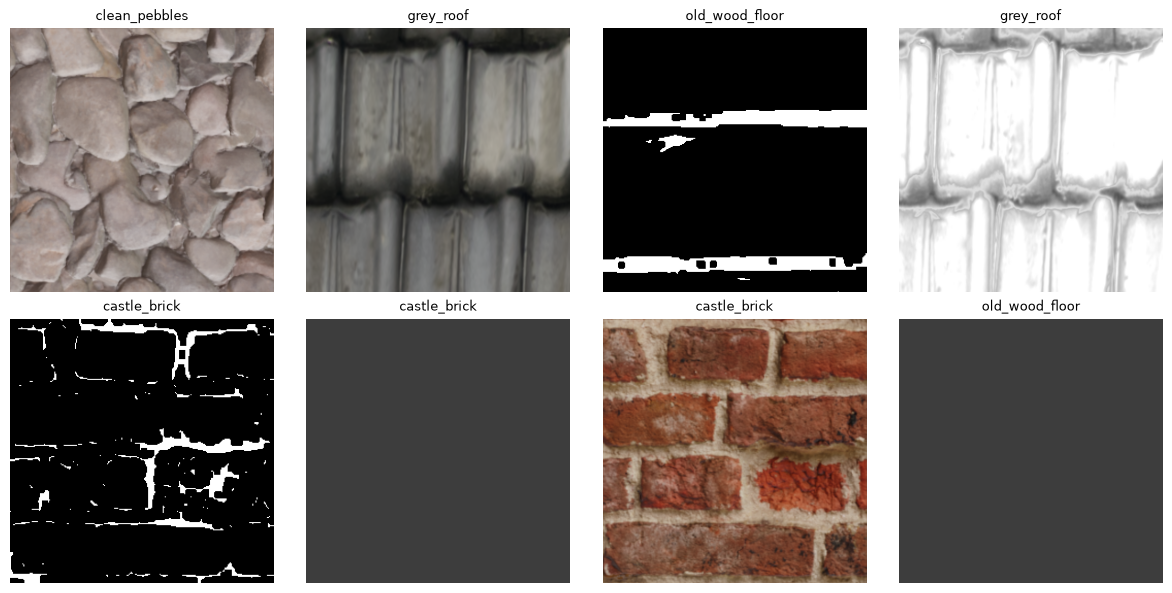

In [19]:
def get_label(p):
    # label = first folder under DATA_ROOT, so images in sub-folders (e.g. "renders") keep their material name
    parts = Path(p).relative_to(DATA_ROOT).parts
    return parts[0] if len(parts) > 1 else Path(p).parent.name

df = pd.DataFrame({"path": [str(p) for p in files]})
df["label"] = [get_label(p) for p in df.path]
classes = sorted(df.label.unique())
class_to_id = {c: i for i, c in enumerate(classes)}
df["label_id"] = df.label.map(class_to_id)

print(f"{len(df)} images, {len(classes)} classes")
print(df.label.value_counts())

sample = df.sample(min(8, len(df)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.path).convert("RGB")); ax.set_title(r.label, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
from collections import Counter

def show_tree(root, max_depth=2, max_items=8):
    root = Path(root)
    def walk(p, depth):
        if depth > max_depth: return
        items = sorted([x for x in p.iterdir() if x.name != ".git"], key=lambda x: (x.is_file(), x.name))
        for x in items[:max_items]:
            print("  " * depth + ("📁 " if x.is_dir() else "📄 ") + x.name)
            if x.is_dir(): walk(x, depth + 1)
        if len(items) > max_items:
            print("  " * depth + f"... (+{len(items) - max_items} more)")
    print(root.name); walk(root, 1)

show_tree(DATA_DIR)
exts = Counter(p.suffix.lower() for p in DATA_DIR.rglob("*") if p.is_file() and ".git" not in p.parts)
print("\nFile types:", exts.most_common(10))

matfuse_1
  📁 imgs
    📄 diffusion.png
    📄 editing.png
    📄 gradio_edit.png
    📄 gradio_generate.png
    📄 teaser.png
  📁 sample_materials
    📁 asphalt_floor
    📁 castle_brick
    📁 clean_pebbles
    📁 grey_roof
    📁 old_wood_floor
  📁 src
    📁 configs
    📁 diffusers_pipeline
    📁 ldm
    📁 scripts
    📁 utils
    📄 gradio_app.py
    📄 main.py
  📄 .gitignore
  📄 LICENSE
  📄 README.md
  📄 requirements.txt

File types: [('.py', 37), ('.png', 35), ('.json', 5), ('', 2), ('.md', 2), ('.yaml', 2), ('.txt', 1)]


## 4. Split

In [20]:
SMALL_DATA = len(df) < 100
if SMALL_DATA:
    # too few images for a separate validation set: 80% train / 20% test, val reuses test
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df.label_id, random_state=SEED)
    val_df = test_df.copy()
else:
    train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label_id, random_state=SEED)
    val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label_id, random_state=SEED)
print("train / val / test:", len(train_df), len(val_df), len(test_df), "| small-data mode:", SMALL_DATA)

class Pixelate:
    def __init__(self, p=0.5, factors=(4, 8, 16)):
        self.p, self.factors = p, factors
    def __call__(self, img):
        if random.random() > self.p: return img
        f = random.choice(self.factors); w, h = img.size
        return img.resize((max(1, w // f), max(1, h // f)), Image.BILINEAR).resize((w, h), Image.NEAREST)

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose(
    [transforms.Resize((IMG_SIZE, IMG_SIZE))]
    + ([Pixelate(0.5)] if PIXELATE_TRAIN else [])
    + [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.ToTensor(), norm])
eval_tf = transforms.Compose(
    [transforms.Resize((IMG_SIZE, IMG_SIZE))]
    + ([Pixelate(1.0)] if PIXELATE_TEST else [])
    + [transforms.ToTensor(), norm])

class ImgDS(Dataset):
    def __init__(self, df, tf):
        self.paths, self.y, self.tf = df.path.tolist(), df.label_id.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.y[i]

def loader(df, tf, shuffle):
    return DataLoader(ImgDS(df, tf), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS)

train_dl, val_dl, test_dl = loader(train_df, train_tf, True), loader(val_df, eval_tf, False), loader(test_df, eval_tf, False)

train / val / test: 24 6 6 | small-data mode: True


## 5. Train (ResNet18, pretrained on ImageNet)

Epoch 1/15  train loss 1.530 acc 0.333 | val loss 1.362 acc 0.333 | 6s
Epoch 2/15  train loss 0.386 acc 0.875 | val loss 1.154 acc 0.333 | 4s
Epoch 3/15  train loss 0.326 acc 0.875 | val loss 1.201 acc 0.333 | 4s
Epoch 4/15  train loss 0.232 acc 0.875 | val loss 1.170 acc 0.500 | 4s
Epoch 5/15  train loss 0.219 acc 0.917 | val loss 0.992 acc 0.500 | 4s
Epoch 6/15  train loss 0.160 acc 0.917 | val loss 0.842 acc 0.500 | 4s
Epoch 7/15  train loss 0.165 acc 0.917 | val loss 0.733 acc 0.833 | 4s
Epoch 8/15  train loss 0.189 acc 0.917 | val loss 0.692 acc 0.833 | 4s
Epoch 9/15  train loss 0.170 acc 0.917 | val loss 0.708 acc 0.833 | 4s
Epoch 10/15  train loss 0.181 acc 0.917 | val loss 0.771 acc 0.667 | 4s
Epoch 11/15  train loss 0.144 acc 0.958 | val loss 0.849 acc 0.667 | 4s
Epoch 12/15  train loss 0.178 acc 0.917 | val loss 0.891 acc 0.667 | 4s
Epoch 13/15  train loss 0.156 acc 0.917 | val loss 0.924 acc 0.667 | 4s
Epoch 14/15  train loss 0.163 acc 0.917 | val loss 0.960 acc 0.667 | 4s
E

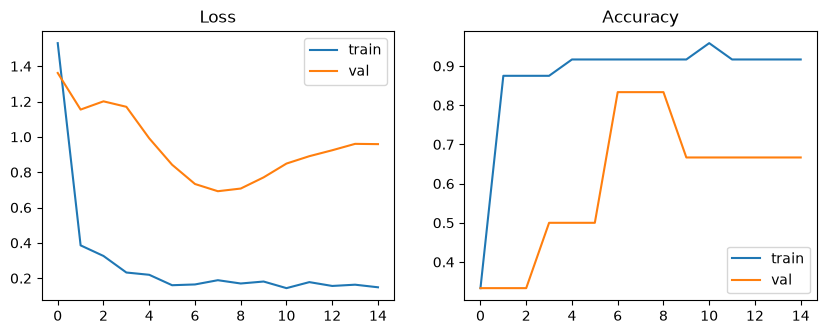

In [21]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(dl, train):
    model.train(train)
    total, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); total += len(y)
    return loss_sum / total, correct / total

Path("checkpoints").mkdir(exist_ok=True)
history, best_val = [], -1.0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_dl, True)
    va_loss, va_acc = run_epoch(val_dl, False)
    scheduler.step()
    history.append((tr_loss, tr_acc, va_loss, va_acc))
    if va_acc > best_val:
        best_val = va_acc
        torch.save({"model": model.state_dict(), "classes": classes}, "checkpoints/best.pt")
    print(f"Epoch {epoch}/{EPOCHS}  train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s")

h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 2], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h[:, 1], label="train"); ax[1].plot(h[:, 3], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## 6. Test: classification

Test accuracy: 0.8333333333333334
                precision    recall  f1-score   support

 asphalt_floor       0.00      0.00      0.00         1
  castle_brick       1.00      1.00      1.00         1
 clean_pebbles       0.50      1.00      0.67         1
     grey_roof       1.00      1.00      1.00         2
old_wood_floor       1.00      1.00      1.00         1

      accuracy                           0.83         6
     macro avg       0.70      0.80      0.73         6
  weighted avg       0.75      0.83      0.78         6



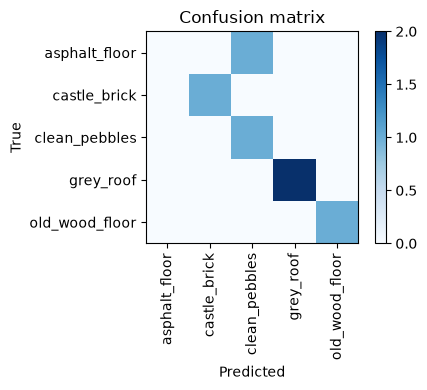

In [22]:
ckpt = torch.load("checkpoints/best.pt", map_location=DEVICE)
model.load_state_dict(ckpt["model"]); model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_dl:
        y_pred += model(x.to(DEVICE)).argmax(1).cpu().tolist(); y_true += y.tolist()

print("Test accuracy:", np.mean(np.array(y_true) == np.array(y_pred)))
labels = list(range(len(classes)))
print(classification_report(y_true, y_pred, labels=labels, target_names=classes, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=labels)
plt.figure(figsize=(max(5, len(classes) * 0.8), max(4, len(classes) * 0.8)))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(len(classes)), classes, rotation=90); plt.yticks(range(len(classes)), classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

## 7. Test: material search (precision@K and ROC AUC)

Test images are queries, training images are the gallery (so a query can never find itself).

In [23]:
backbone = nn.Sequential(*list(model.children())[:-1]).to(DEVICE).eval()   # ResNet18 without the final layer

@torch.no_grad()
def embed(df):
    feats = []
    for x, _ in loader(df, eval_tf, False):
        f = backbone(x.to(DEVICE)).flatten(1)
        feats.append(nn.functional.normalize(f, dim=1).cpu())
    return torch.cat(feats)

gallery_df = train_df.reset_index(drop=True) if SMALL_DATA else pd.concat([train_df, val_df]).reset_index(drop=True)
G, Q = embed(gallery_df), embed(test_df)
g_labels, q_labels = gallery_df.label_id.values, test_df.label_id.values

K = 3 if SMALL_DATA else 5
sims = Q @ G.T
topk = sims.topk(K, dim=1).indices.numpy()
print(f"Precision@{K}: {(g_labels[topk] == q_labels[:, None]).mean():.3f}")

same = (q_labels[:, None] == g_labels[None, :]).astype(int)
print(f"ROC AUC (same material vs different): {roc_auc_score(same.ravel(), sims.numpy().ravel()):.3f}")

Precision@3: 0.611
ROC AUC (same material vs different): 0.704


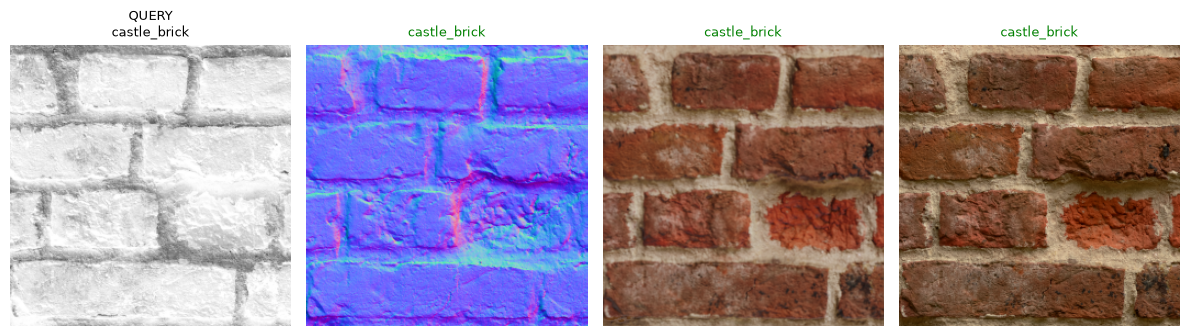

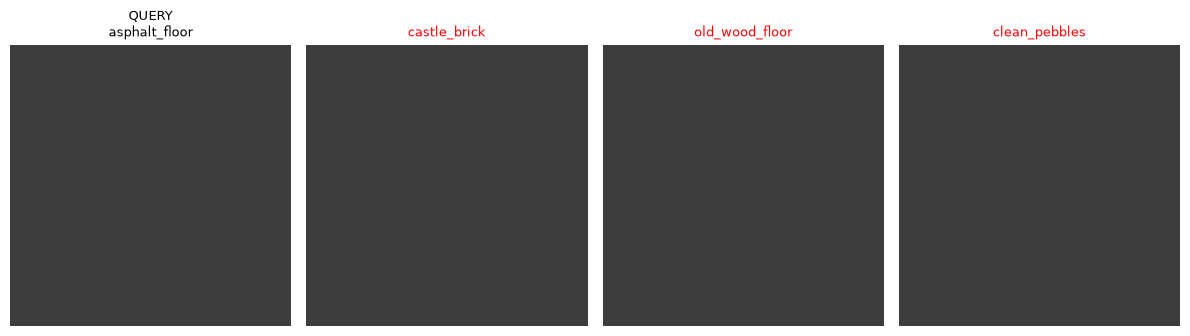

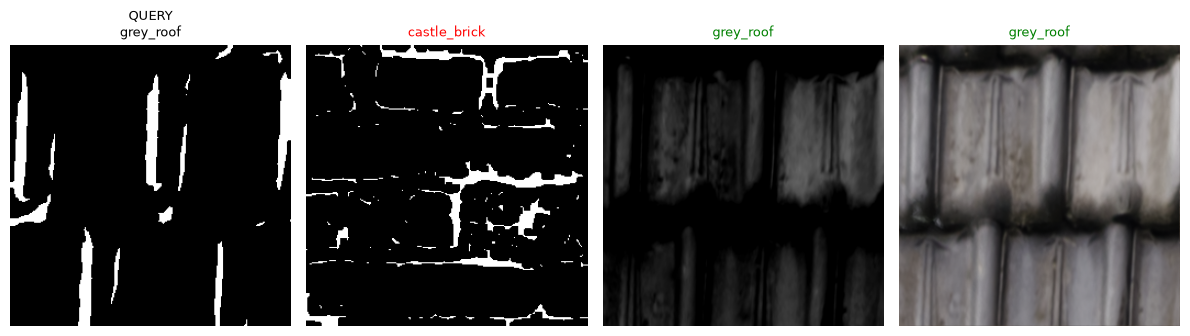

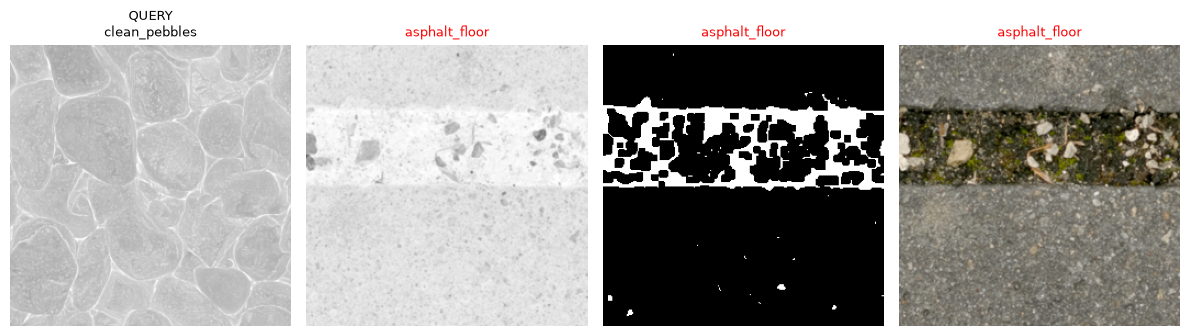

In [24]:
def show_search(query_idx):
    idx = topk[query_idx]
    fig, axes = plt.subplots(1, K + 1, figsize=(3 * (K + 1), 3.4))
    axes[0].imshow(Image.open(test_df.path.iloc[query_idx]).convert("RGB"))
    axes[0].set_title("QUERY\n" + test_df.label.iloc[query_idx], fontsize=9); axes[0].axis("off")
    for ax, gi in zip(axes[1:], idx):
        ax.imshow(Image.open(gallery_df.path.iloc[gi]).convert("RGB"))
        ok = g_labels[gi] == q_labels[query_idx]
        ax.set_title(gallery_df.label.iloc[gi], fontsize=9, color="green" if ok else "red"); ax.axis("off")
    plt.tight_layout(); plt.show()

for i in random.sample(range(len(test_df)), min(4, len(test_df))):
    show_search(i)

## 8. Try it on any image

In [25]:
def predict(path, top=3):
    img = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(model(img), 1)[0].cpu()
    vals, ids = probs.topk(min(top, len(classes)))
    for v, i in zip(vals, ids): print(f"{classes[i]:<25} {v:.1%}")

predict(test_df.path.iloc[0])
# predict(r"C:\path\to\your\own\image.png")

clean_pebbles             34.2%
castle_brick              29.1%
old_wood_floor            24.1%


#### TESTING

In [26]:
all_df = df.reset_index(drop=True).copy()
E = embed(all_df)                          # embeddings for every image
S = E @ E.T
S.fill_diagonal_(-1)                       # an image can't retrieve itself

K = 3
top = S.topk(K, dim=1).indices.numpy()
labels = all_df.label_id.values

all_df["split"] = np.where(all_df.path.isin(test_df.path), "test", "train")
all_df["precision_at_k"] = (labels[top] == labels[:, None]).mean(axis=1)
all_df["top1_correct"] = labels[top[:, 0]] == labels

print(all_df.groupby("split")[["precision_at_k", "top1_correct"]].mean().round(3))
print()
print(all_df.groupby("label")[["precision_at_k", "top1_correct"]].mean().round(3))

# the individual images where search failed
all_df[all_df.precision_at_k < 1][["path", "label", "split", "precision_at_k"]]

       precision_at_k  top1_correct
split                              
test            0.611         0.500
train           0.833         0.833

                precision_at_k  top1_correct
label                                       
asphalt_floor            0.833         0.833
castle_brick             0.778         0.667
clean_pebbles            0.556         0.667
grey_roof                0.944         0.833
old_wood_floor           0.833         0.833


,path,label,split,precision_at_k
4,C:\Users\ugome\OneDrive\Documents\hackathon-te...,asphalt_floor,test,0.000000
8,C:\Users\ugome\OneDrive\Documents\hackathon-te...,castle_brick,train,0.666667
9,C:\Users\ugome\OneDrive\Documents\hackathon-te...,castle_brick,train,0.000000
12,C:\Users\ugome\OneDrive\Documents\hackathon-te...,clean_pebbles,test,0.000000
13,C:\Users\ugome\OneDrive\Documents\hackathon-te...,clean_pebbles,train,0.333333
14,C:\Users\ugome\OneDrive\Documents\hackathon-te...,clean_pebbles,train,0.000000
18,C:\Users\ugome\OneDrive\Documents\hackathon-te...,grey_roof,test,0.666667
24,C:\Users\ugome\OneDrive\Documents\hackathon-te...,old_wood_floor,train,0.000000


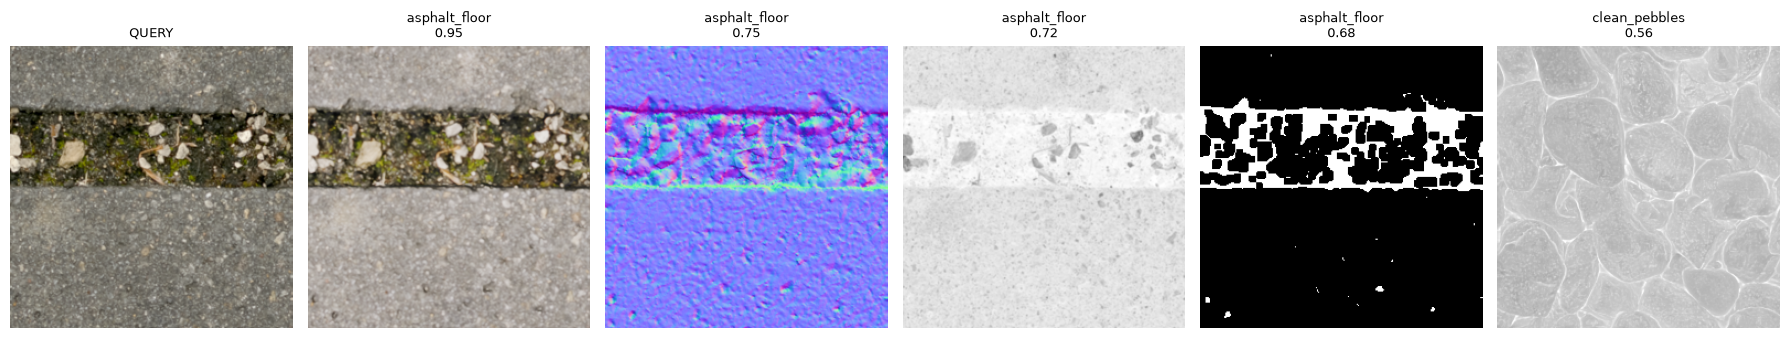

Best guess: asphalt_floor (4/5 results)


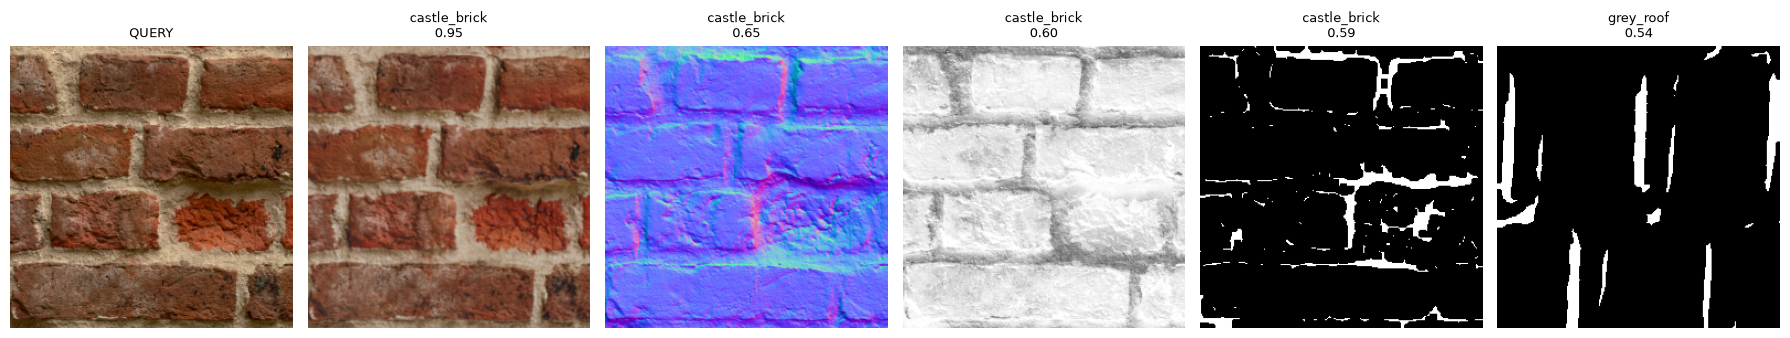

Best guess: castle_brick (4/5 results)


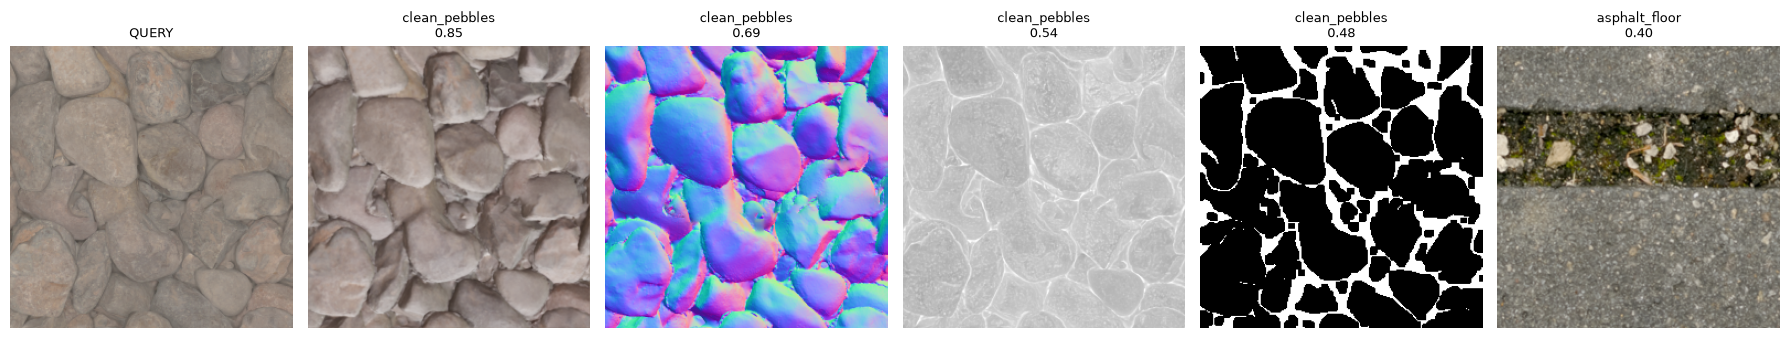

Best guess: clean_pebbles (4/5 results)


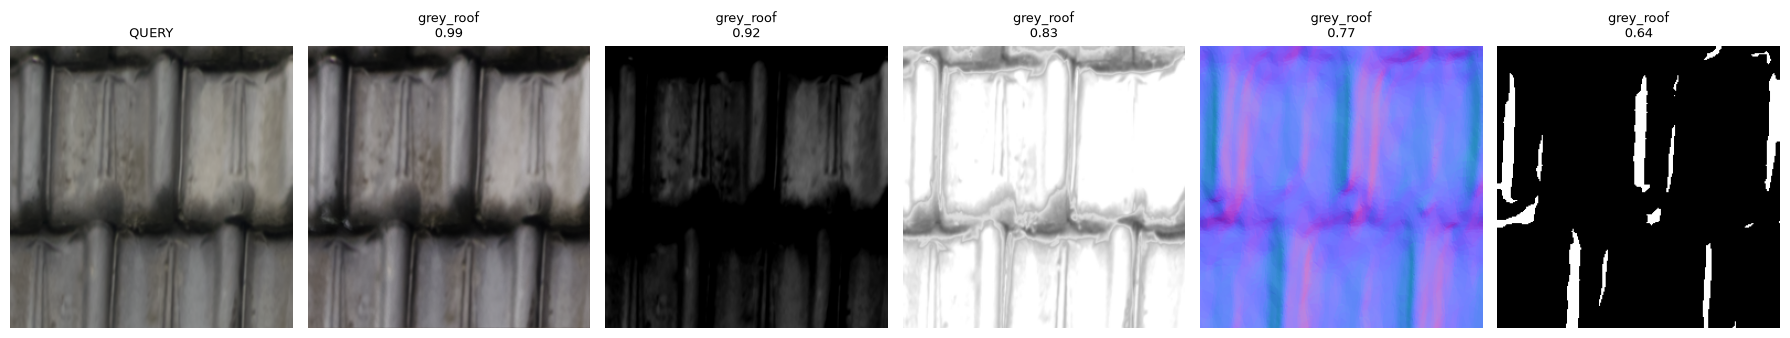

Best guess: grey_roof (5/5 results)


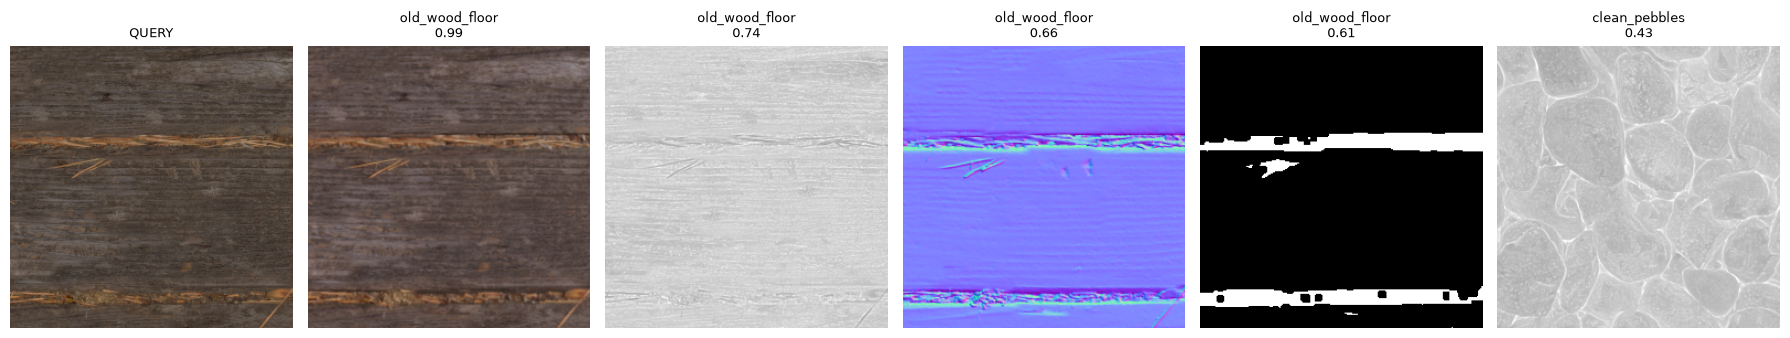

Best guess: old_wood_floor (4/5 results)


In [27]:
@torch.no_grad()
def search(path, k=5):
    k = min(k, len(all_df) - 1)
    img = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)
    q = nn.functional.normalize(backbone(img).flatten(1), dim=1).cpu()
    sims = (q @ E.T)[0]
    sims[torch.tensor((all_df.path == str(Path(path))).values)] = -1   # skip the same file
    vals, idx = sims.topk(k)

    fig, axes = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3.6))
    axes[0].imshow(Image.open(path).convert("RGB")); axes[0].set_title("QUERY", fontsize=9); axes[0].axis("off")
    for ax, v, i in zip(axes[1:], vals, idx):
        ax.imshow(Image.open(all_df.path[int(i)]).convert("RGB"))
        ax.set_title(f"{all_df.label[int(i)]}\n{v:.2f}", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

    votes = all_df.label.iloc[idx.numpy()].value_counts()
    print("Best guess:", votes.index[0], f"({votes.iloc[0]}/{k} results)")

# one query per material
for p in all_df.groupby("label").head(1).path:
    search(p)

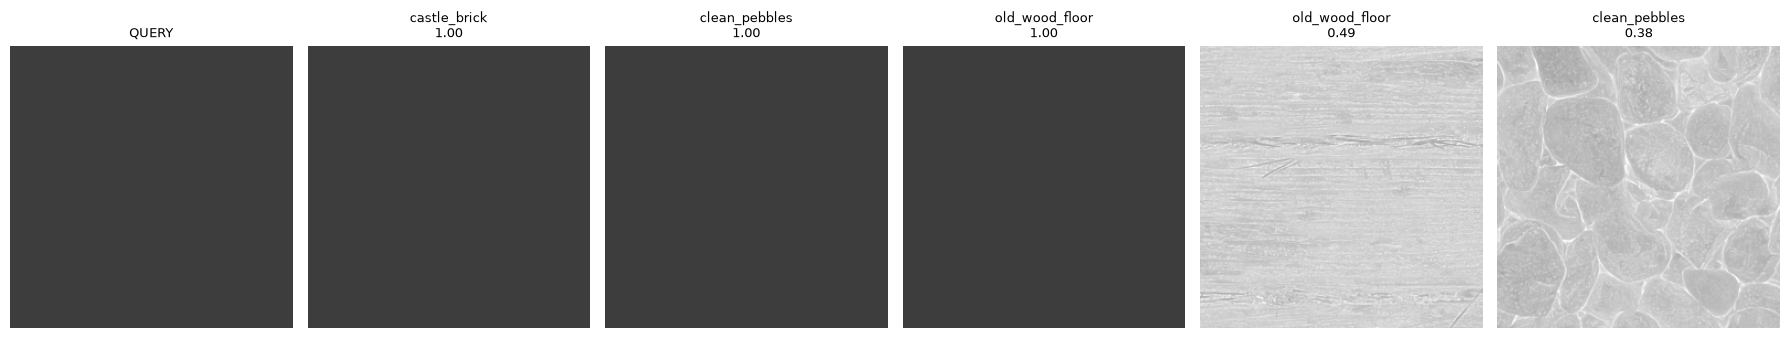

Best guess: clean_pebbles (2/5 results)


In [30]:
search(test_df.path.iloc[0])